In [19]:
import numpy as np
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("M4 GPU devices:", tf.config.list_physical_devices("GPU"))
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import image_dataset_from_directory
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras import layers
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# warnings.filterwarnings("ignore")
tf.random.set_seed(42)
np.random.seed(42)

dataset_dir = "dataset/Plant_leaf_diseases_dataset_without_augmentation/Plant_leave_diseases_dataset_without_augmentation"
batch_size = 32
image_size = (256, 256)
image_shape = (256, 256, 3)
val_split = 0.2

# crop_disease_train_data = image_dataset_from_directory(
#                                 'dataset/Plant_leaf_diseases_dataset_without_augmentation\\Plant_leave_diseases_dataset_without_augmentation',
#                                 labels="inferred",
#                                 label_mode="categorical",
#                                 class_names=None,
#                                 color_mode="rgb",
#                                 batch_size=32,
#                                 image_size=image_size,
#                                 shuffle=True,
#                                 seed=123,
#                                 interpolation="bilinear",
#                                 verbose=True,
#                             )

train_data = image_dataset_from_directory(
    dataset_dir,
    validation_split=val_split,
    subset="training",
    seed=123,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True,
    label_mode="categorical",
    color_mode="rgb",
)

# Validation dataset
val_data = image_dataset_from_directory(
    dataset_dir,
    validation_split=val_split,
    subset="validation",
    seed=123,
    image_size=image_size,
    batch_size=batch_size,
    shuffle=True,
    label_mode="categorical",
    color_mode="rgb",
)

try:
    base_model = tf.keras.applications.MobileNetV3Small(
        input_shape=(256, 256, 3), include_top=False, weights="imagenet", pooling="avg"
    )

    for layer in base_model.layers:
        layer.trainable = False

    print("✅ MobileNetV3Small loaded successfully")
except Exception as e:
    print(f"❌ Error loading MobileNetV3Small: {e}")


print(50 * "-")
num_classes = len(train_data.class_names)
print(f"Num of classes: {num_classes}")

TensorFlow version: 2.16.2
M4 GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 55446 files belonging to 39 classes.
Using 44357 files for training.
Found 55446 files belonging to 39 classes.
Using 11089 files for validation.


/Applications/Developer/python/Ai/Crop-Disease-Detection/crop_venv/lib/python3.11/site-packages/keras/src/applications/mobilenet_v3.py:452: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


✅ MobileNetV3Small loaded successfully
--------------------------------------------------
Num of classes: 39


In [20]:
classes = train_data.class_names
print(f"Classes: {classes}")
print(50 * "-")

Classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Background_without_leaves', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_Yellow_

2025-10-24 08:31:46.736674: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


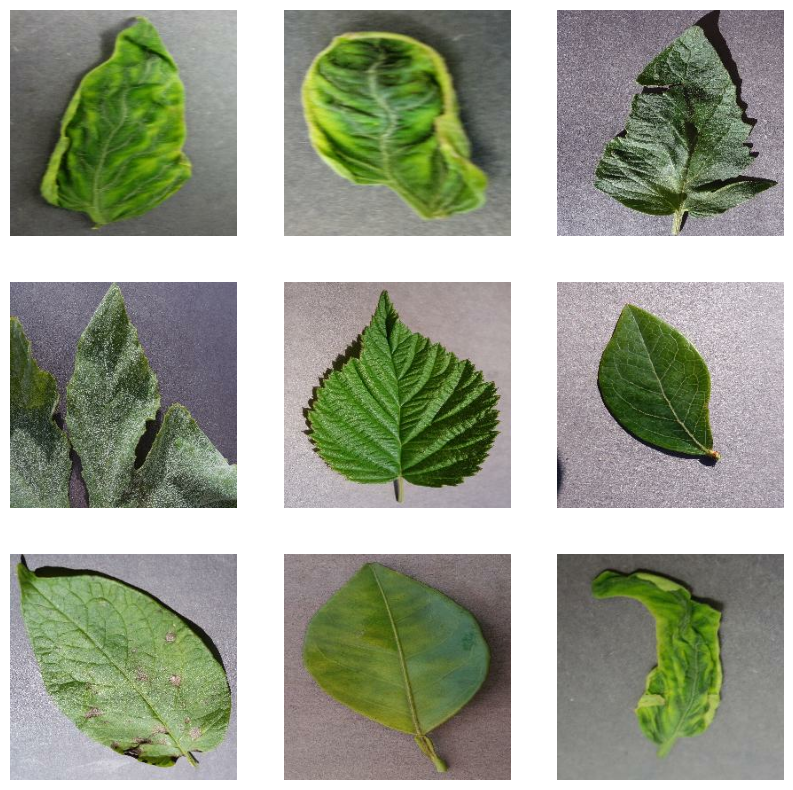

In [2]:
plt.figure(figsize=(10, 10))
for images, labels in train_data.take(1):
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.axis("off")
plt.show()

In [3]:
# val_size = int(0.2 * len(crop_disease_train_data))
# val_data = crop_disease_train_data.take(val_size)
# train_data = crop_disease_train_data.skip(val_size)

AUTOTUNE = tf.data.AUTOTUNE
train_data = train_data.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_data = val_data.cache().prefetch(buffer_size=AUTOTUNE)

data_augementation = Sequential(
    [
        layers.Rescaling(1.0 / 255, input_shape=image_shape),
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.2),
        layers.RandomZoom(0.2),
    ]
)


/Applications/Developer/python/Ai/Crop-Disease-Detection/crop_venv/lib/python3.11/site-packages/keras/src/layers/preprocessing/tf_data_layer.py:19: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [4]:
model = Sequential(
    [
        layers.InputLayer(input_shape=image_shape),
        base_model,
        layers.Dense(256, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(num_classes),
    ]
)

model.summary()

/Applications/Developer/python/Ai/Crop-Disease-Detection/crop_venv/lib/python3.11/site-packages/keras/src/layers/core/input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ MobileNetV3Small (Functional)   │ (None, 576)            │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       147,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 39)             │        10,023 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,096,855 (4.18 MB)

 Trainable params: 157,735 (616.15 KB)

 Non-trainable params: 939,120 (3.58 MB)

In [5]:
model.compile(
    Adam(learning_rate=1e-4),
    loss=CategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"],
)

checkpoint = ModelCheckpoint(
    filepath="best_model.keras",
    monitor="val_accuracy",
    mode="max",
    save_best_only=True,
    verbose=1,
)

early_stop = EarlyStopping(
    monitor="val_accuracy", mode="max", patience=5, restore_best_weights=True, verbose=1
)

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=4,
    callbacks=[checkpoint, early_stop],
)

Epoch 1/4


2025-10-24 08:31:47.454720: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


1387/1387 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.5055 - loss: 1.9880
Epoch 1: val_accuracy improved from None to 0.90405, saving model to best_model.h5


1387/1387 ━━━━━━━━━━━━━━━━━━━━ 185s 127ms/step - accuracy: 0.6947 - loss: 1.2143 - val_accuracy: 0.9040 - val_loss: 0.4139
Epoch 2/4
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step - accuracy: 0.8863 - loss: 0.4276
Epoch 2: val_accuracy improved from 0.90405 to 0.94292, saving model to best_model.h5


1387/1387 ━━━━━━━━━━━━━━━━━━━━ 224s 161ms/step - accuracy: 0.8994 - loss: 0.3749 - val_accuracy: 0.9429 - val_loss: 0.2303
Epoch 3/4
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 0s 151ms/step - accuracy: 0.9228 - loss: 0.2704
Epoch 3: val_accuracy improved from 0.94292 to 0.95780, saving model to best_model.h5


1387/1387 ━━━━━━━━━━━━━━━━━━━━ 267s 193ms/step - accuracy: 0.9307 - loss: 0.2452 - val_accuracy: 0.9578 - val_loss: 0.1686
Epoch 4/4
1387/1387 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9457 - loss: 0.1920
Epoch 4: val_accuracy improved from 0.95780 to 0.96267, saving model to best_model.h5


1387/1387 ━━━━━━━━━━━━━━━━━━━━ 302s 218ms/step - accuracy: 0.9467 - loss: 0.1853 - val_accuracy: 0.9627 - val_loss: 0.1370
Restoring model weights from the end of the best epoch: 4.


In [ ]:
model.save("crop_disease_detection.keras")

(256, 256, 3)


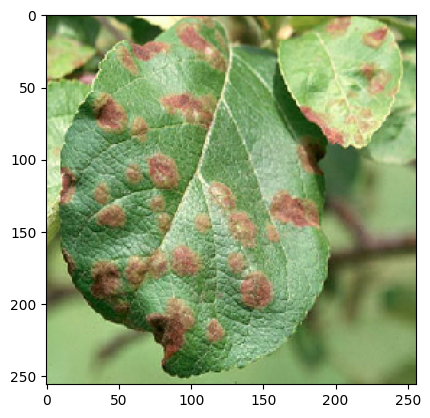

In [14]:
test_image = tf.keras.utils.load_img("dataset/applescab-leaf.jpg", target_size=(256, 256))
input_array = tf.keras.utils.img_to_array(test_image)
print(input_array.shape)
input_array = np.expand_dims(input_array, axis=0)  # Create batch axis
plt.imshow(test_image)

In [21]:
model = tf.keras.models.load_model("crop_disease_detection.keras")
predictions = model.predict(input_array)
predicted_class = tf.argmax(predictions[0]).numpy()
print(f"Predicted class: {classes[predicted_class]}")

/Applications/Developer/python/Ai/Crop-Disease-Detection/crop_venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 6 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 792ms/step
Predicted class: Strawberry___Leaf_scorch


In [ ]:
# x = base_model.output
# x = tf.keras.layers.GlobalAveragePooling2D()(x)

# embedding_model = tf.keras.models.Model(inputs=base_model.input, outputs = x)

In [ ]:
# all_embeddings = []
# all_labels = []

# for images, labels in crop_disease_train_data:
#     batch_embeddings = embedding_model.predict(images)
#     all_embeddings.extend(batch_embeddings)
#     all_labels.extend(labels.numpy())

# embeddings = np.array(all_embeddings)
# labels = np.array(all_labels)

# print(f"Generated embeddings with shape: {embeddings.shape}")
# print(f"Corresponding labels with shape: {labels.shape}")

In [ ]:
import os
import glob

# Your base dataset directory
base_dir = "dataset/Plant_leaf_diseases_dataset_without_augmentation\\Plant_leave_diseases_dataset_without_augmentation"

# Get a list of all class subdirectories
class_directories = [
    d for d in glob.glob(os.path.join(base_dir, "*")) if os.path.isdir(d)
]
len(class_directories)


In [ ]:
# import numpy as np
# from sklearn.cluster import DBSCAN
# from tensorflow.keras.preprocessing import image
# from tensorflow.keras.applications.vgg16 import preprocess_input

# for class_dir in class_directories[20:22]:
#     print(f"Processing directory: {class_dir}")
#     image_paths = glob.glob(os.path.join(class_dir, '*.jpg'))

#     if len(image_paths) < 2:
#         print(f"Skipping {class_dir}: Not enough images to perform clustering.")
#         continue

#     local_embeddings = []
#     for image_path in image_paths:
#         img = image.load_img(image_path, target_size=(224,224))
#         img_array = image.img_to_array(img)
#         img_array_expanded = np.expand_dims(img_array, axis=0)
#         img_preprocessed = preprocess_input(img_array_expanded)

#         embedding = embedding_model.predict(img_preprocessed, verbose = 0)[0]
#         local_embeddings.append(embedding)

#     local_embeddings = np.array(local_embeddings)
#     dbscan = DBSCAN(eps=0.3, min_samples=7,metric='cosine')
#     clusters = dbscan.fit_predict(local_embeddings)

#     anomaly_indices = np.where(clusters == -1)[0]

#     if len(anomaly_indices) > 0:
#         print(f"Found {len(anomaly_indices)} anomaly images in {class_dir}:")
#         for index in anomaly_indices:
#             anomaly_path = image_paths[index]
#             print(f"  Anomaly detected: {anomaly_path}") # D:\Developer\Python\AI\Projects\CropDisease\dataset\Plant_leaf_diseases_dataset_without_augmentation\Plant_leave_diseases_dataset_without_augmentation\Pepper,_bell___healthy
#     else:
#         print(f"No anomalies found in {class_dir}")
